In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam


2025-07-03 17:14:25.560219: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 17:14:25.560277: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_DNN-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_label']

In [6]:
# Load precomputed selected features
feature_list_path = "selected_features_binary_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.4, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=42)

In [8]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1050542, 40)
X_val shape: (116727, 40)
X_test shape: (778180, 40)


In [9]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [10]:
def create_binary_classification_dnn(input_shape, dropout_rate=0.5, learning_rate=0.001):
    model = Sequential([
        Dense(128, activation='relu', input_shape=input_shape),
        Dropout(dropout_rate),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(32, activation='relu'),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')  # Binary output
    ])

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

In [11]:
input_shape = (X_train.shape[1],)
model = create_binary_classification_dnn(input_shape)
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               5248      
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dropout_2 (Dropout)         (None, 32)                0         
                                                                 
 dense_3 (Dense)             (None, 1)                 3

2025-07-03 17:15:16.337209: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-07-03 17:15:16.341158: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 17:15:16.341553: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-07-03 17:15:16.341909: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-07-03 17:15:16.342312: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

In [12]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("DNN_2(60-40)" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [13]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=6,
                    batch_size=32,
                    callbacks=[early_stop, model_checkpoint])
# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/6
32829/32830 [============================>.] - ETA: 0s - loss: 0.0025 - accuracy: 0.9996
Epoch 00001: val_accuracy improved from -inf to 1.00000, saving model to DNN_2(60-40).h5
32830/32830 [==============================] - 136s 4ms/step - loss: 0.0025 - accuracy: 0.9996 - val_loss: 0.0000e+00 - val_accuracy: 1.0000
Epoch 2/6
32825/32830 [============================>.] - ETA: 0s - loss: 2.6721e-04 - accuracy: 1.0000
Epoch 00002: val_accuracy did not improve from 1.00000
32830/32830 [==============================] - 128s 4ms/step - loss: 2.6717e-04 - accuracy: 1.0000 - val_loss: 0.0000e+00 - val_accuracy: 1.0000
Epoch 3/6
32827/32830 [============================>.] - ETA: 0s - loss: 1.3500e-04 - accuracy: 1.0000
Epoch 00003: val_accuracy did not improve from 1.00000
32830/32830 [==============================] - 139s 4ms/step - loss: 1.3499e-04 - accuracy: 1.0000 - val_loss: 0.0000e+00 - val_accuracy: 1.0000
Epoch 4/6
32826/32830 [============================>.] - ETA: 0s 

In [14]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.102883 seconds


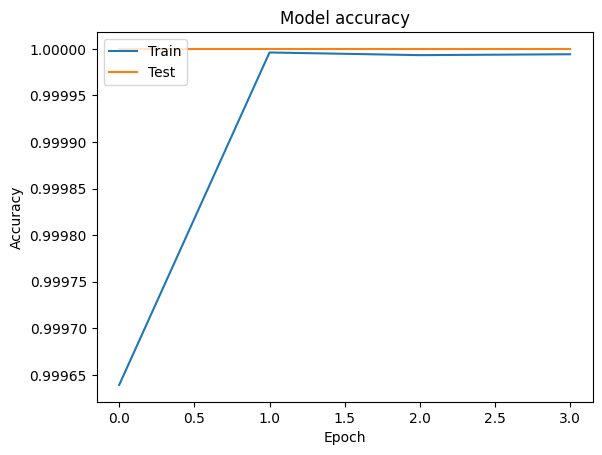

In [15]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

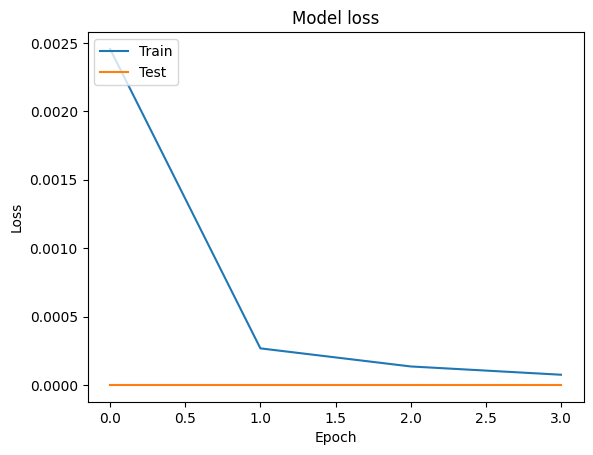

In [16]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [17]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [18]:
# Performance comparison table
print(classification_report(y_test, np.round(y_pred), target_names=['No Intrusion', 'Intrusion']))

              precision    recall  f1-score   support

No Intrusion       1.00      1.00      1.00    560180
   Intrusion       1.00      1.00      1.00    218000

    accuracy                           1.00    778180
   macro avg       1.00      1.00      1.00    778180
weighted avg       1.00      1.00      1.00    778180



In [19]:
auc = roc_auc_score(y_test, y_pred)
print(f"AUC: {auc:.4f}")

AUC: 1.0000


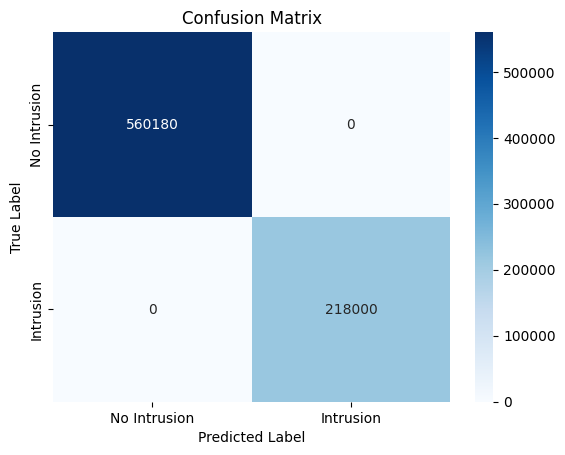

In [20]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, np.round(y_pred))

# Define the class labels
class_labels = ['No Intrusion', 'Intrusion']

# Create a heatmap plot of the confusion matrix
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)

# Set the plot labels and title
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

# Show the plot
plt.show()
# plt.savefig('con_max.jpg')

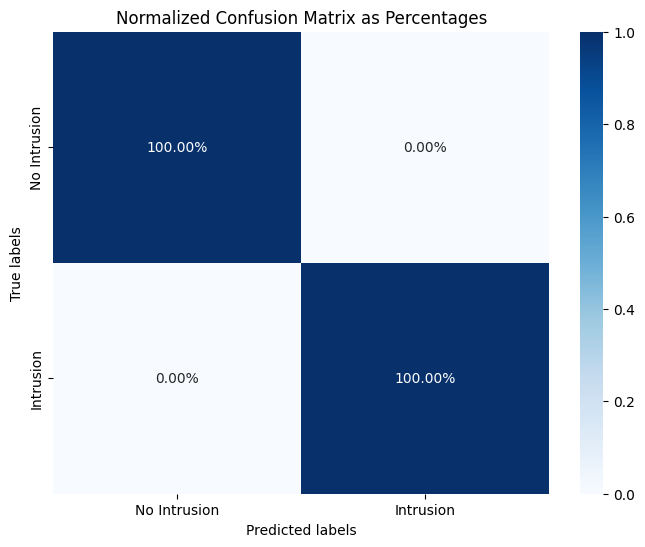

In [21]:
# Predict the test set
y_pred = (y_pred > 0.5)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
# Define the class labels
class_labels = ['No Intrusion', 'Intrusion']
# Print confusion matrix as heatmap with percentages
plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, fmt='.2%')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')